# LG-EffNetV2-S (proposed Lesion-Guided EfficientNetV2-S): DR grading with grade + lesion multi-task learning
MMRDR CFP dataset, TensorFlow/Keras. Set `CFG["train"] = True` to retrain; by default trained weights are loaded.

## 0. Setup
Imports, configuration (`CFG`), seeds and GPU settings.

In [1]:
import io
import json
import math
import os
import platform
import random
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")              # hide TensorFlow start-up noise
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import ndimage, stats
from scipy.special import log_softmax, softmax
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import sklearn
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, cohen_kappa_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
import tensorflow as tf
import keras
from keras import layers
from PIL import Image

ON_KAGGLE = Path("/kaggle/input").exists()
SMOKE = os.environ.get("DRXAI_SMOKE", "0") == "1"

CFG = dict(
    train=os.environ.get("DRXAI_TRAIN", "0") == "1",
    weights_dataset="effnetv2s-v3-dr-weights",
    seed=42,
    img_size=512,
    val_frac=0.125,                # 7:1 train:val, as in the MMRDR evaluation code
    batch_size=16,
    epochs_phase1=10,              # phase 1: frozen backbone, head only
    epochs_phase2=25,
    lr_phase1=1e-3,                # head-only training: normal learning rate
    lr_phase2=1e-4,
    weight_decay=1e-4,
    head_units=256,                # hidden layer of the custom head
    head_dropout=0.3,
    class_weight_power=0.5,        # sqrt inverse-frequency class weights
    patience=6,
    label_smoothing=0.1,
    ema_momentum=0.998,
    lesion_loss_weight=0.5,
    lesion_dropout=0.3,
    mixed_precision=True,
    n_bootstrap=1000,
    referral_rate=0.20,            # confidence threshold set on VAL to refer 20 %
    dup_hamming=2,
)
if SMOKE:
    CFG.update(img_size=128, batch_size=8, epochs_phase1=2, epochs_phase2=2, n_bootstrap=50)

MODEL_NAME = "effnetv2s_v3_tf"
GRADES = ["No DR", "Mild NPDR", "Moderate NPDR", "Severe NPDR", "PDR"]
LESIONS = ["MA", "HE", "IH", "VB/IRMA", "NV", "VH", "RD"]
K = len(GRADES)
SIZE = CFG["img_size"]


def seed_everything(seed):
    """Fix Python, NumPy and TensorFlow seeds (GPU kernels may still differ in the last decimals)."""
    random.seed(seed); np.random.seed(seed); keras.utils.set_random_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


gpus = tf.config.list_physical_devices("GPU")
if gpus:
    tf.config.set_visible_devices(gpus[0], "GPU")
    tf.config.experimental.set_memory_growth(gpus[0], True)
MIXED = CFG["mixed_precision"] and (bool(gpus) or os.environ.get("DRXAI_FORCE_MIXED") == "1")   # env var: test on CPU
keras.mixed_precision.set_global_policy("mixed_float16" if MIXED else "float32")
seed_everything(CFG["seed"])
AUTOTUNE = tf.data.AUTOTUNE

ROOT = Path("/kaggle/working") if ON_KAGGLE else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
OUT_DIR = Path(os.environ.get("DRXAI_OUT", ROOT / "outputs_effnetv2s_v3_tf"))
if SMOKE:
    OUT_DIR = OUT_DIR / "smoke"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(OUT_DIR / "config.json", "w"), indent=2)


def savefig(name):
    plt.savefig(OUT_DIR / "figures" / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


print(f"MODE: {'TRAINING' if CFG['train'] else 'LOADING TRAINED WEIGHTS (no training)'}")
print(f"GPU: {gpus[0].name if gpus else 'none (CPU)'} | mixed precision={MIXED} | smoke={SMOKE} kaggle={ON_KAGGLE} out={OUT_DIR}")
print("python", platform.python_version(), "| tensorflow", tf.__version__, "| keras", keras.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| scipy", scipy.__version__)

MODE: LOADING TRAINED WEIGHTS (no training)
GPU: /physical_device:GPU:0 | mixed precision=True | smoke=False kaggle=True out=/kaggle/working/outputs_effnetv2s_v3_tf
python 3.13.15 | tensorflow 2.20.0 | keras 3.13.2 | numpy 2.1.3 | pandas 2.3.3 | sklearn 1.6.1 | scipy 1.16.3


## 1. Load data
Locate the preprocessed MMRDR CFP dataset (512×512) and read the labels.

In [2]:
def find_data_dir():
    cands = [os.environ.get("DRXAI_DATA", ""), str(ROOT / "data" / "cfp512")]
    if ON_KAGGLE:
        cands += [str(p.parent) for p in Path("/kaggle/input").rglob("FP.csv")]
    for c in cands:
        if c and (Path(c) / "FP.csv").exists() and (Path(c) / "img").is_dir():
            return Path(c)
    raise FileNotFoundError("Attach the Kaggle dataset 'mmrdr-cfp512' (or set DRXAI_DATA).")


DATA_DIR = find_data_dir()
IMG_DIR = DATA_DIR / "img"
df = pd.read_csv(DATA_DIR / "FP.csv")
df["file"] = df["image"].str.split("/").str[-1]
df["split"] = np.where(df["file"].str.startswith("ts"), "test", "train")
L = np.array([json.loads(s) for s in df["lesion"]], dtype=np.int64)
for i, name in enumerate(LESIONS):
    df[name] = L[:, i]

print(f"DATA_DIR = {DATA_DIR} | {len(df)} labelled images")

DATA_DIR = /kaggle/input/datasets/mariajabeen01/mmrdr-cfp512/cfp512 | 11118 labelled images


## 2. Data inspection
### 2.1 Grade distribution
Class counts per split; the data are heavily imbalanced (≈59 % No DR).

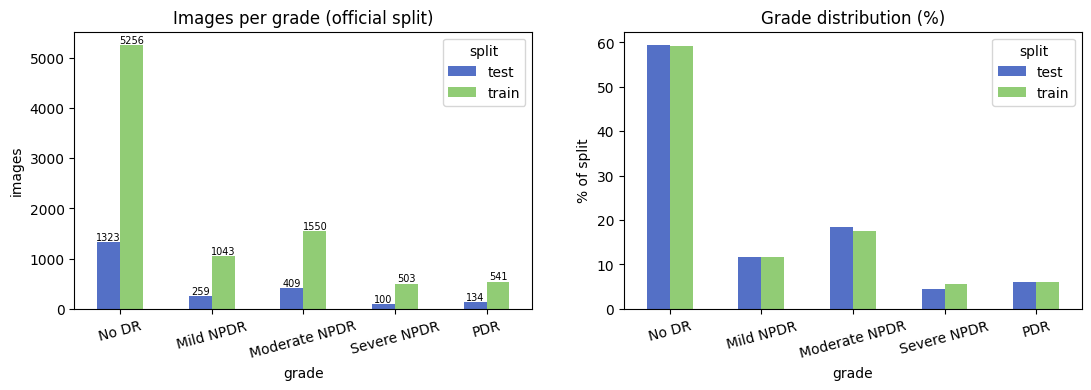

Imbalance ratio (largest/smallest train class): 10.4x | majority-class accuracy on test: 0.595 | laterality L/R: 5607/5511


split,test,train,train %,test %
grade,,,,
No DR,1323,5256,59.1,59.5
Mild NPDR,259,1043,11.7,11.6
Moderate NPDR,409,1550,17.4,18.4
Severe NPDR,100,503,5.7,4.5
PDR,134,541,6.1,6.0


In [3]:
counts = pd.crosstab(df["grade"], df["split"]).rename(index=dict(enumerate(GRADES)))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
counts.plot.bar(ax=axs[0], rot=15, color=["#5470c6", "#91cc75"])
for c in axs[0].containers:
    axs[0].bar_label(c, fontsize=7)
axs[0].set_title("Images per grade (official split)"); axs[0].set_ylabel("images")
(counts / counts.sum() * 100).plot.bar(ax=axs[1], rot=15, color=["#5470c6", "#91cc75"])
axs[1].set_title("Grade distribution (%)"); axs[1].set_ylabel("% of split")
savefig("01_grade_distribution")
imb = counts["train"].max() / counts["train"].min()
print(f"Imbalance ratio (largest/smallest train class): {imb:.1f}x | majority-class accuracy on test: "
      f"{(df[df.split == 'test'].grade == 0).mean():.3f} | laterality L/R: {(df.lr == 0).sum()}/{(df.lr == 1).sum()}")
display(counts.assign(**{"train %": (100 * counts.train / counts.train.sum()).round(1),
                         "test %": (100 * counts.test / counts.test.sum()).round(1)}))

### 2.2 Lesions vs grade
Lesion prevalence per grade and grading-rule checks on the labels.

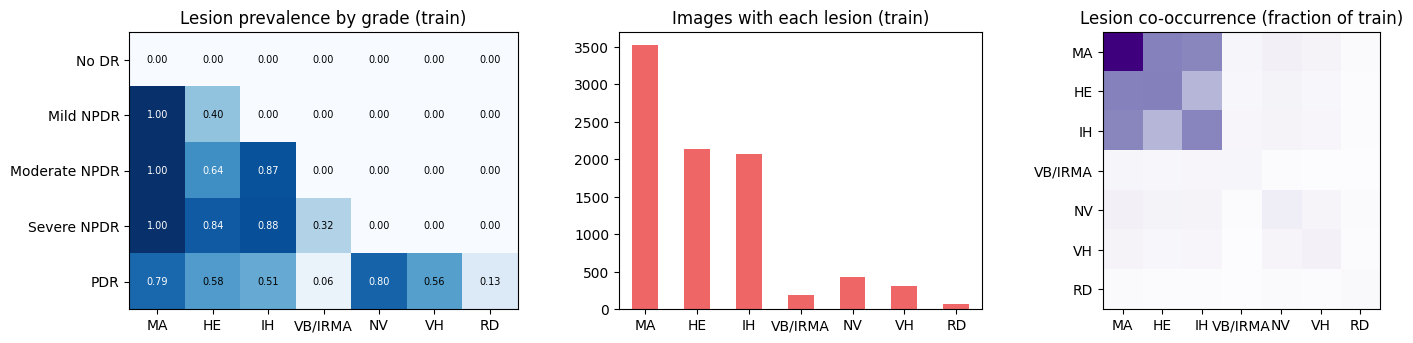

Lowest grade at which each lesion occurs: {'MA': 1, 'HE': 1, 'IH': 2, 'VB/IRMA': 3, 'NV': 4, 'VH': 4, 'RD': 4}
Rule violations in the ground truth (all images): {'under_graded_vs_lesions': 0, 'dr_without_lesions': 0, 'pdr_without_pdr_lesion': 0, 'npdr_without_ma': 0, 'no_dr_with_lesions': 0}
Mild NPDR with hard exudates: 537 / 1302 (the paper defines Mild NPDR as microaneurysms only)
Severe NPDR with VB/IRMA: 197 / 603 (most severe cases are defined by lesion extent, which presence flags cannot express)


In [4]:
tr_lab = df[df.split == "train"]
prev = tr_lab.groupby("grade")[LESIONS].mean().rename(index=dict(enumerate(GRADES)))
co = tr_lab[LESIONS].T.dot(tr_lab[LESIONS]) / len(tr_lab)
fig, axs = plt.subplots(1, 3, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
im = axs[0].imshow(prev.values, cmap="Blues", vmin=0, vmax=1)
axs[0].set_xticks(range(7), LESIONS); axs[0].set_yticks(range(K), prev.index)
for (r, c), v in np.ndenumerate(prev.values):
    axs[0].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > .6 else "black")
axs[0].set_title("Lesion prevalence by grade (train)")
tr_lab[LESIONS].sum().plot.bar(ax=axs[1], rot=0, color="#ee6666"); axs[1].set_title("Images with each lesion (train)")
axs[2].imshow(co.values, cmap="Purples"); axs[2].set_xticks(range(7), LESIONS); axs[2].set_yticks(range(7), LESIONS)
axs[2].set_title("Lesion co-occurrence (fraction of train)")
savefig("02_lesions")

MIN_GRADE = {l: int(tr_lab.loc[tr_lab[l] == 1, "grade"].min()) for l in LESIONS}
PDR_LESIONS = [l for l in LESIONS if MIN_GRADE[l] == 4]


def rule_violations(grade, present, absent=None):
    """Grade/lesion combinations that contradict the grading protocol (ICDR-style 4-2-1 rule)."""
    present = present.astype(bool)
    absent = ~present if absent is None else absent.astype(bool)
    implied = np.where(present, np.array([MIN_GRADE[l] for l in LESIONS])[None, :], 0).max(1)
    pdr = [LESIONS.index(l) for l in PDR_LESIONS]
    return pd.DataFrame({
        "under_graded_vs_lesions": grade < implied,
        "dr_without_lesions": (grade >= 1) & absent.all(1),
        "pdr_without_pdr_lesion": (grade == 4) & absent[:, pdr].all(1),
        "npdr_without_ma": np.isin(grade, [1, 2, 3]) & absent[:, LESIONS.index("MA")],
        "no_dr_with_lesions": (grade == 0) & present.any(1),
    })


print("Lowest grade at which each lesion occurs:", MIN_GRADE)
print("Rule violations in the ground truth (all images):", rule_violations(df.grade.values, df[LESIONS].values).sum().to_dict())
print(f"Mild NPDR with hard exudates: {((df.grade == 1) & (df.HE == 1)).sum()} / {(df.grade == 1).sum()} "
      f"(the paper defines Mild NPDR as microaneurysms only)")
print(f"Severe NPDR with VB/IRMA: {((df.grade == 3) & (df['VB/IRMA'] == 1)).sum()} / {(df.grade == 3).sum()} "
      f"(most severe cases are defined by lesion extent, which presence flags cannot express)")

### 2.3 Image quality
Brightness, contrast and sharpness per image, with the worst examples.

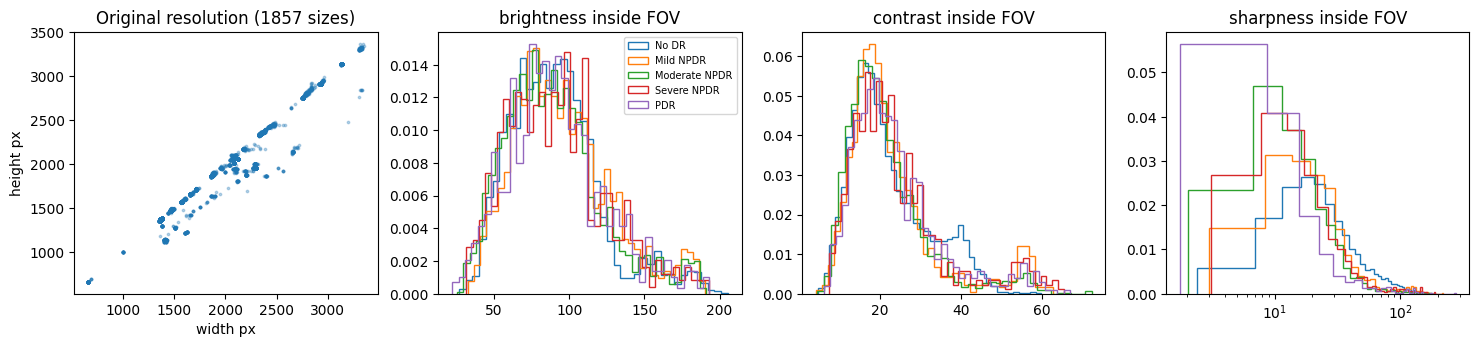

Lowest-5% sharpness images: 556; very dark (brightness < 40): 161; very bright (> 200): 3


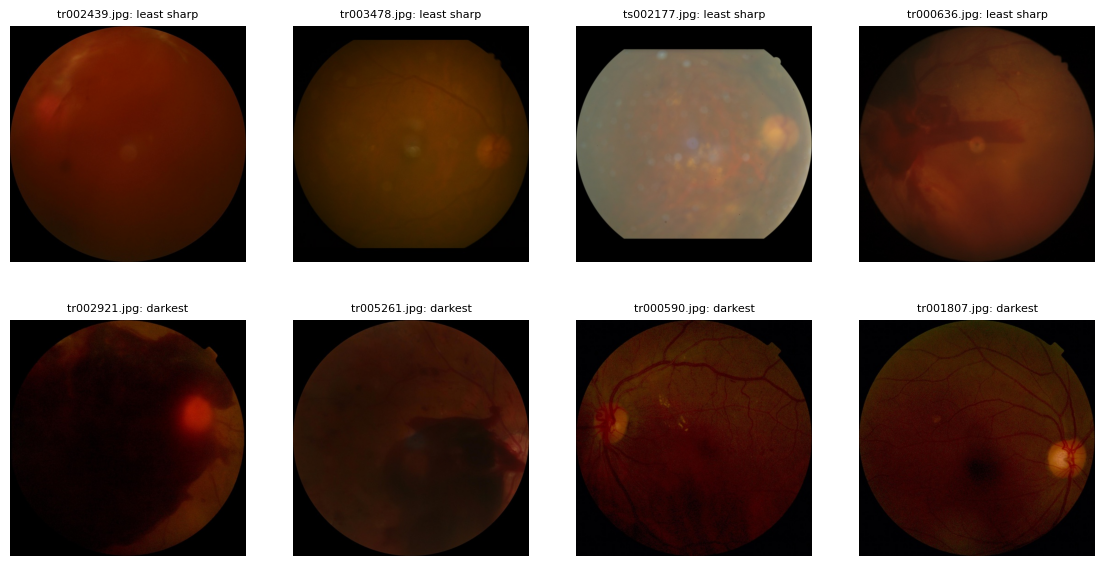

In [5]:
def image_stats(path):
    a = np.asarray(Image.open(path).convert("RGB").resize((256, 256), Image.BILINEAR), dtype=np.float32)
    fov = ndimage.binary_erosion(a.max(2) > 15, iterations=6)
    g = a.mean(2); lap = ndimage.laplace(g)
    d = np.asarray(Image.open(path).convert("L").resize((17, 16), Image.BILINEAR), dtype=np.int16)
    ok = fov.any()
    return dict(brightness=g[fov].mean() if ok else 0., contrast=g[fov].std() if ok else 0.,
                sharpness=lap[fov].var() if ok else 0., red=a[..., 0][fov].mean() if ok else 0.,
                dhash=np.packbits((d[:, 1:] > d[:, :-1]).flatten()).tobytes().hex())


stats_path = OUT_DIR / "image_stats.csv"
if stats_path.exists():
    st = pd.read_csv(stats_path)
else:
    with ThreadPoolExecutor(max_workers=os.cpu_count() or 4) as ex:
        st = pd.DataFrame(list(ex.map(image_stats, [IMG_DIR / f for f in df["file"]]))).assign(file=df["file"].values)
    st.to_csv(stats_path, index=False)
df = df.merge(st, on="file", how="left")
meta = pd.read_csv(DATA_DIR / "prep_meta.csv").drop_duplicates("image")
df = df.merge(meta[["image", "orig_w", "orig_h"]], on="image", how="left")

fig, axs = plt.subplots(1, 4, figsize=(18, 3.4))
axs[0].scatter(df.orig_w, df.orig_h, s=3, alpha=.3); axs[0].set_title(f"Original resolution ({df[['orig_w', 'orig_h']].drop_duplicates().shape[0]} sizes)")
axs[0].set_xlabel("width px"); axs[0].set_ylabel("height px")
for ax, col in zip(axs[1:], ["brightness", "contrast", "sharpness"]):
    for g in range(K):
        ax.hist(df.loc[df.grade == g, col], bins=40, histtype="step", density=True, label=GRADES[g])
    ax.set_title(f"{col} inside FOV")
axs[3].set_xscale("log"); axs[1].legend(fontsize=7)
savefig("03_quality_proxies")
q_lo = df.sharpness.quantile(0.05)
print(f"Lowest-5% sharpness images: {(df.sharpness < q_lo).sum()}; very dark (brightness < 40): {(df.brightness < 40).sum()}; "
      f"very bright (> 200): {(df.brightness > 200).sum()}")

fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for ax, f in zip(axs[0], df.sort_values("sharpness").file.head(4)):
    ax.imshow(Image.open(IMG_DIR / f)); ax.axis("off"); ax.set_title(f"{f}: least sharp", fontsize=8)
for ax, f in zip(axs[1], df.sort_values("brightness").file.head(4)):
    ax.imshow(Image.open(IMG_DIR / f)); ax.axis("off"); ax.set_title(f"{f}: darkest", fontsize=8)
savefig("04_low_quality_examples")

### 2.4 Duplicates
Find near-identical photographs with a difference hash (dHash).

Exact-duplicate pairs: 153 | groups: 133 (275 images) | groups spanning train+test: 44 -> 45 test images leak | groups with CONFLICTING grades: 3


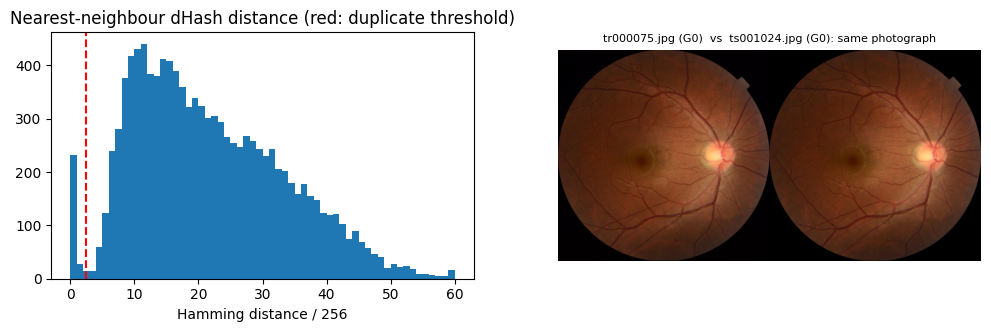

In [6]:
def hamming_groups(hex_list, thr, chunk=128):
    """Connected components of 'Hamming distance <= thr' over all images, plus each image's nearest neighbour."""
    H = np.stack([np.frombuffer(bytes.fromhex(h), np.uint8) for h in hex_list])
    pop = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(1).astype(np.uint8)
    rows, cols, nn_d = [], [], np.empty(len(H), int)
    for s in range(0, len(H), chunk):
        d = pop[H[s:s + chunk, None, :] ^ H[None, :, :]].sum(2, dtype=np.int32)
        d[np.arange(d.shape[0]), np.arange(s, s + d.shape[0])] = 999
        nn_d[s:s + chunk] = d.min(1)
        r, c = np.nonzero(d <= thr); keep = (r + s) < c
        rows.append(r[keep] + s); cols.append(c[keep])
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    groups = connected_components(coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(H),) * 2), directed=False)[1]
    return groups, nn_d, list(zip(rows, cols))


df["dup_group"], df["nn_hamming"], dup_pairs = hamming_groups(df.dhash.values, CFG["dup_hamming"])
g = df.groupby("dup_group").agg(n=("file", "size"), grades=("grade", "nunique"), splits=("split", lambda x: "+".join(sorted(set(x)))))
multi = g[g.n > 1]
te_dup_groups = set(multi[multi.splits == "test+train"].index)
df["test_dup_of_train"] = (df.split == "test") & df.dup_group.isin(te_dup_groups)
print(f"Exact-duplicate pairs: {len(dup_pairs)} | groups: {len(multi)} ({multi.n.sum()} images) | "
      f"groups spanning train+test: {len(te_dup_groups)} -> {df.test_dup_of_train.sum()} test images leak | "
      f"groups with CONFLICTING grades: {(multi.grades > 1).sum()}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
axs[0].hist(df.nn_hamming.clip(upper=60), bins=60); axs[0].axvline(CFG["dup_hamming"] + .5, color="r", ls="--")
axs[0].set_title("Nearest-neighbour dHash distance (red: duplicate threshold)"); axs[0].set_xlabel("Hamming distance / 256")
for (i, j), ax in zip(dup_pairs[:1], [axs[1]]):
    ax.imshow(np.concatenate([np.asarray(Image.open(IMG_DIR / df.file[i])), np.asarray(Image.open(IMG_DIR / df.file[j]))], 1))
    ax.axis("off"); ax.set_title(f"{df.file[i]} (G{df.grade[i]})  vs  {df.file[j]} (G{df.grade[j]}): same photograph", fontsize=8)
savefig("05_duplicates")

### 2.5 Examples
Sample training images per grade with their annotated lesions.

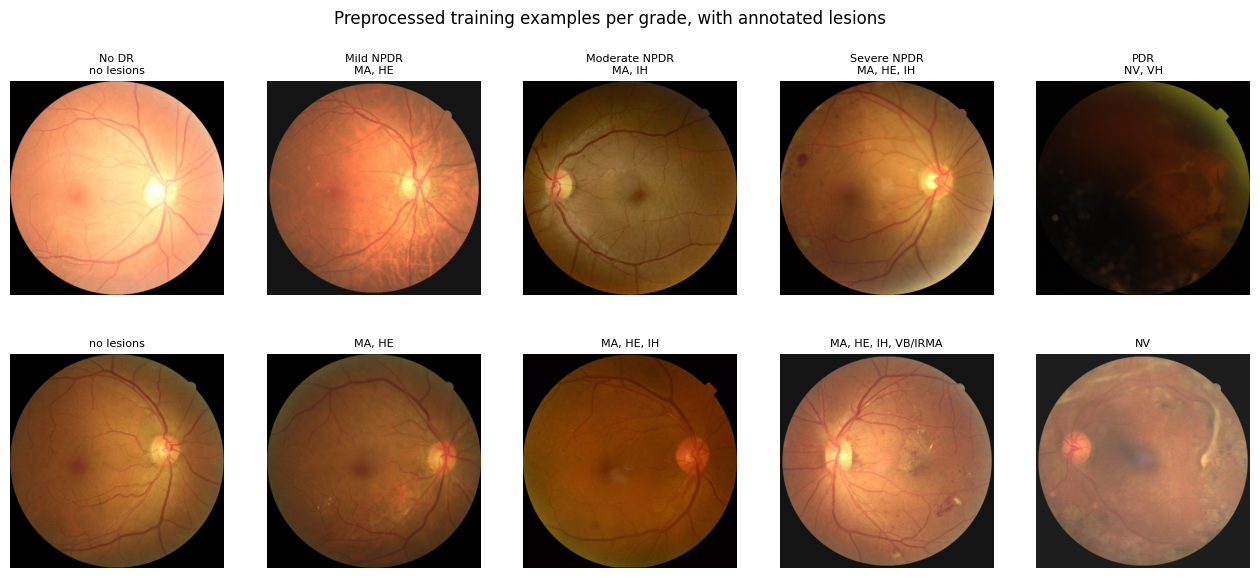

In [7]:
fig, axs = plt.subplots(2, K, figsize=(16, 6.5))
r = np.random.default_rng(CFG["seed"])
for g_ in range(K):
    fs = df[(df.split == "train") & (df.grade == g_)].file.values
    for row in range(2):
        f = r.choice(fs)
        axs[row, g_].imshow(Image.open(IMG_DIR / f)); axs[row, g_].axis("off")
        les = ", ".join(l for l in LESIONS if df.loc[df.file == f, l].item() == 1) or "no lesions"
        axs[row, g_].set_title((GRADES[g_] + "\n" if row == 0 else "") + les, fontsize=8)
plt.suptitle("Preprocessed training examples per grade, with annotated lesions")
savefig("06_examples_per_grade")

## 3. Augmentation
On-the-fly crop, flips, rotation and colour jitter (no hue shift); images stay in [0, 255].
 Keras' EfficientNetV2-S contains its own preprocessing layer (`rescaling`, enabled by
`include_preprocessing=True`) as the first layer of the model.

I0000 00:00:1793017269.167910      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


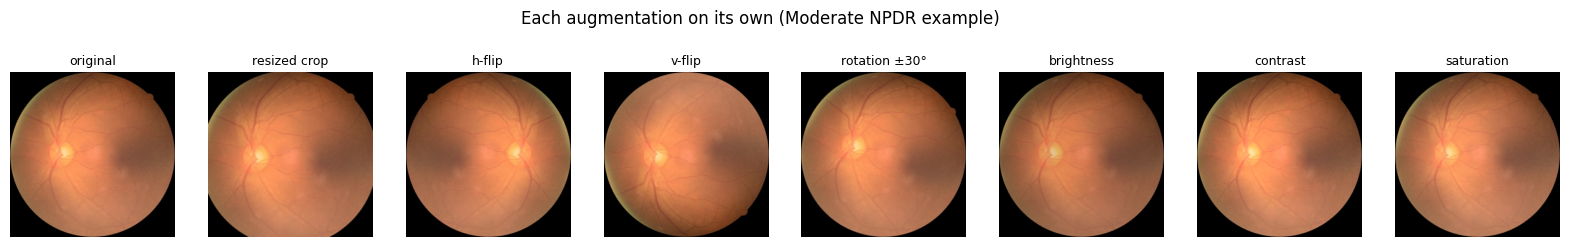

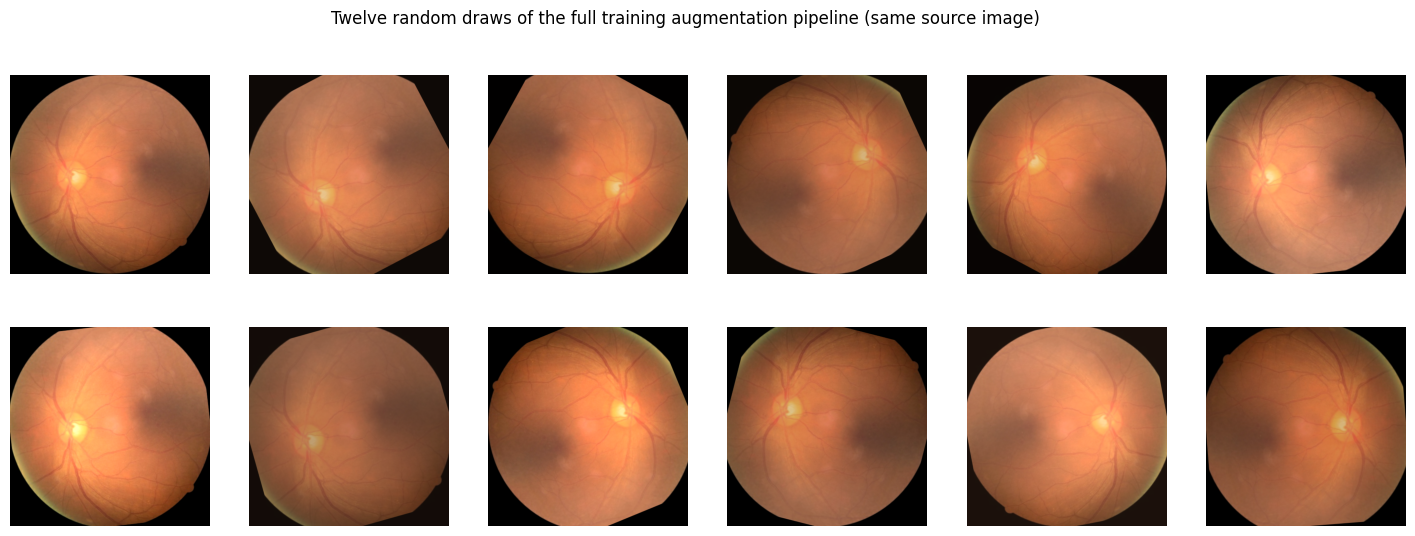

In [8]:
def preprocess(img):
    """Keras EfficientNetV2 normalises inside the model (rescaling layer): pass raw RGB 0-255 through."""
    return img


def to_display(x):
    """Image in [0, 255] -> [0, 1] for plotting."""
    return np.clip(np.asarray(x, dtype=np.float32) / 255.0, 0, 1)


def load_image(path):
    """Read a preprocessed 512-px JPEG as float32 RGB in [0, 255] (resized only in the smoke test)."""
    img = tf.cast(tf.io.decode_jpeg(tf.io.read_file(path), channels=3), tf.float32)
    return tf.image.resize(img, (SIZE, SIZE)) if SIZE != 512 else tf.ensure_shape(img, (512, 512, 3))


def random_resized_crop(img, scale=(0.85, 1.0), ratio=(0.95, 1.05)):
    h, w = tf.cast(tf.shape(img)[0], tf.float32), tf.cast(tf.shape(img)[1], tf.float32)
    area = h * w * tf.random.uniform([], *scale)
    r = tf.exp(tf.random.uniform([], math.log(ratio[0]), math.log(ratio[1])))
    ch = tf.cast(tf.minimum(tf.sqrt(area / r), h), tf.int32)
    cw = tf.cast(tf.minimum(tf.sqrt(area * r), w), tf.int32)
    return tf.image.resize(tf.image.random_crop(img, tf.stack([ch, cw, 3])), (SIZE, SIZE))


rotate = layers.RandomRotation(30 / 360, fill_mode="constant", fill_value=0.0, seed=CFG["seed"], dtype="float32")


def augment(img):
    """Training augmentation on a float32 RGB image in [0, 255]."""
    img = random_resized_crop(img)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.cast(rotate(img, training=True), tf.float32)
    x = img / 255.0
    x = x * tf.random.uniform([], 0.8, 1.2)                        # brightness ±20 %
    x = tf.image.random_contrast(x, 0.8, 1.2)                      # contrast ±20 %
    x = tf.image.random_saturation(tf.clip_by_value(x, 0, 1), 0.9, 1.1)   # saturation ±10 %, no hue change
    return tf.clip_by_value(x, 0.0, 1.0) * 255.0


demo_path = str(IMG_DIR / df[(df.split == "train") & (df.grade == 2)].file.iloc[0])
demo = load_image(demo_path)
single = {"original": lambda im: im,
          "resized crop": random_resized_crop,
          "h-flip": tf.image.flip_left_right, "v-flip": tf.image.flip_up_down,
          "rotation ±30°": lambda im: tf.cast(rotate(im, training=True), tf.float32),
          "brightness": lambda im: tf.clip_by_value(im * tf.random.uniform([], 0.8, 1.2), 0, 255),
          "contrast": lambda im: tf.clip_by_value(tf.image.random_contrast(im, 0.8, 1.2), 0, 255),
          "saturation": lambda im: tf.image.random_saturation(im / 255.0, 0.9, 1.1) * 255.0}
tf.random.set_seed(1)
fig, axs = plt.subplots(1, len(single), figsize=(20, 3))
for ax, (nm, t) in zip(axs, single.items()):
    ax.imshow(np.clip(np.asarray(t(demo), dtype=np.float32) / 255.0, 0, 1)); ax.axis("off"); ax.set_title(nm, fontsize=9)
plt.suptitle("Each augmentation on its own (Moderate NPDR example)")
savefig("07_augmentation_individual")
fig, axs = plt.subplots(2, 6, figsize=(18, 6))
for ax in axs.flat:
    ax.imshow(to_display(preprocess(augment(demo)))); ax.axis("off")
plt.suptitle("Twelve random draws of the full training augmentation pipeline (same source image)")
savefig("08_augmentation_pipeline")

## 4. Data split
Stratified train/validation split grouped by duplicate; official test set held out.
* **Validation set:** 12.5 % of the official training split (7:1, as in the MMRDR evaluation code), **stratified
  by grade and grouped by duplicate group**, so copies of one photograph never straddle train and validation.
  Used for early stopping (validation QWK), temperature scaling and the referral threshold.

,train,val,test
No DR,4582,674,1323
Mild NPDR,911,132,259
Moderate NPDR,1368,182,409
Severe NPDR,440,63,100
PDR,482,59,134


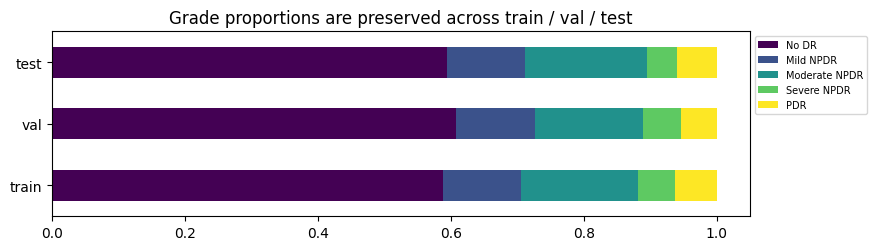

In [9]:
dev = df[df.split == "train"].reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=round(1 / CFG["val_frac"]), shuffle=True, random_state=CFG["seed"])
tr_i, va_i = next(sgkf.split(dev, dev["grade"], groups=dev["dup_group"]))
tr_df, va_df, te_df = dev.iloc[tr_i], dev.iloc[va_i], df[df.split == "test"]
assert not set(tr_df.dup_group) & set(va_df.dup_group)
if SMOKE:
    take = lambda d, n: pd.concat([x.sample(min(len(x), n), random_state=0) for _, x in d.groupby("grade")])
    tr_df, va_df, te_df = take(tr_df, 24), take(va_df, 12), take(te_df, 16)
tr_df, va_df, te_df = (d.reset_index(drop=True) for d in (tr_df, va_df, te_df))
pd.concat([tr_df.assign(subset="train"), va_df.assign(subset="val"), te_df.assign(subset="test")])[
    ["file", "grade", "subset"]].to_csv(OUT_DIR / "split.csv", index=False)
split_tbl = pd.DataFrame({n: d.grade.value_counts().sort_index() for n, d in [("train", tr_df), ("val", va_df), ("test", te_df)]})
split_tbl.index = GRADES
display(split_tbl)
(split_tbl / split_tbl.sum()).T.plot.barh(stacked=True, figsize=(9, 2.4), colormap="viridis")
plt.title("Grade proportions are preserved across train / val / test"); plt.legend(fontsize=7, bbox_to_anchor=(1, 1))
savefig("09_split")

### 4.1 Datasets and loss weights
`tf.data` pipelines, sqrt inverse-frequency class weights and lesion positive weights.

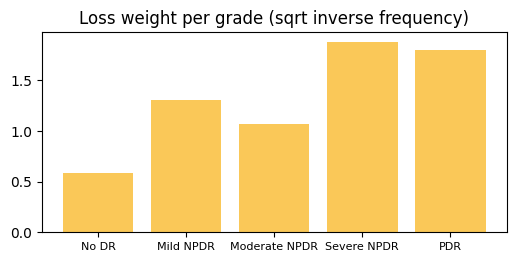

lesion prevalence (train): {'MA': np.float64(0.398), 'HE': np.float64(0.242), 'IH': np.float64(0.234), 'VB/IRMA': np.float64(0.023), 'NV': np.float64(0.049), 'VH': np.float64(0.035), 'RD': np.float64(0.008)} | positive weights: {'MA': np.float32(1.23), 'HE': np.float32(1.77), 'IH': np.float32(1.81), 'VB/IRMA': np.float32(6.57), 'NV': np.float32(4.4), 'VH': np.float32(5.29), 'RD': np.float32(10.0)}


In [10]:
freq = np.bincount(tr_df.grade, minlength=K) / len(tr_df)
CLASS_W = ((1 / (K * np.maximum(freq, 1e-6))) ** CFG["class_weight_power"]).astype(np.float32)


def make_ds(frame, train, perturb=None, batch_size=None):
    """tf.data pipeline yielding (preprocessed image, grade, class weight, 7 lesion labels). `perturb` degrades images."""
    paths = [str(IMG_DIR / f) for f in frame["file"]]
    y = frame["grade"].values.astype(np.int32)
    les = frame[LESIONS].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, y, CLASS_W[y], les))
    if train:
        ds = ds.shuffle(len(paths), seed=CFG["seed"], reshuffle_each_iteration=True)

    def _map(p, label, w, lesion):
        img = load_image(p)
        if train:
            img = augment(img)
        if perturb is not None:
            img = perturb(img)
        return preprocess(img), label, w, lesion

    return (ds.map(_map, num_parallel_calls=AUTOTUNE)
              .batch(batch_size or CFG["batch_size"], drop_remainder=train).prefetch(AUTOTUNE))


fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(GRADES, CLASS_W, color="#fac858"); ax.set_title("Loss weight per grade (sqrt inverse frequency)")
ax.tick_params(axis="x", labelsize=8); savefig("10_class_weights")

lp = tr_df[LESIONS].values.mean(0)
LESION_POS_W = np.clip(np.sqrt((1 - lp) / np.maximum(lp, 1e-6)), 1, 10).astype(np.float32)   # rare lesions weigh more
print("lesion prevalence (train):", dict(zip(LESIONS, lp.round(3))), "| positive weights:", dict(zip(LESIONS, LESION_POS_W.round(2))))

## 5. Model
LG-EffNetV2-S: EfficientNetV2-S backbone with a grade head (5 classes) and a lesion head (7 sigmoid outputs).
1. **Phase 1, frozen backbone:** a freshly initialised head produces large, random gradients. Training only the head
   first (backbone `trainable=False`) means those gradients cannot damage the pretrained features.
2. **Phase 2, fine-tuning:** the backbone is unfrozen (`trainable=True`) **except its BatchNorm layers**, which stay
   frozen and in inference mode. The learning rate is 10× smaller, so the features adapt gently to fundus images.

In [11]:
def build_model(weights="imagenet"):
    """LG-EffNetV2-S: EfficientNetV2-S backbone + grade head + lesion head. Outputs a dict of float32 logits:
    {"grade": (N, 5), "lesion": (N, 7)}. Input: raw RGB in [0, 255]."""
    inp = keras.Input((SIZE, SIZE, 3), name="image")
    base = keras.applications.EfficientNetV2S(include_top=False, weights=weights, input_tensor=inp,
                                              include_preprocessing=True)
    feat = layers.GlobalAveragePooling2D(name="head_gap")(base.output)
    x = layers.BatchNormalization(name="head_bn1")(feat)
    x = layers.Dropout(CFG["head_dropout"], name="head_drop1")(x)
    x = layers.Dense(CFG["head_units"], activation="relu", name="head_dense")(x)
    x = layers.BatchNormalization(name="head_bn2")(x)
    x = layers.Dropout(CFG["head_dropout"], name="head_drop2")(x)
    grade = layers.Dense(K, dtype="float32", name="head_out")(x)
    l = layers.Dropout(CFG["lesion_dropout"], name="head_lesion_drop")(feat)
    lesion = layers.Dense(len(LESIONS), dtype="float32", name="head_lesion_out")(l)
    return keras.Model(inp, {"grade": grade, "lesion": lesion}, name="effnetv2s_dr_multitask")


model = build_model(weights="imagenet" if CFG["train"] else None)   # trained weights are loaded in Section 6
HEAD = [l for l in model.layers if l.name.startswith("head_")]
BACKBONE = [l for l in model.layers if not l.name.startswith("head_") and not isinstance(l, keras.layers.InputLayer)]


def set_phase(phase):
    """Phase 1: freeze the whole backbone. Phase 2: unfreeze it except its BatchNorm layers."""
    for l in BACKBONE:
        l.trainable = (phase == 2) and not isinstance(l, layers.BatchNormalization)
    for l in HEAD:
        l.trainable = True


n_params = lambda vs: sum(int(np.prod(v.shape)) for v in vs) / 1e6
for ph in (1, 2):
    set_phase(ph)
    print(f"phase {ph}: trainable {n_params(model.trainable_variables):.2f} M of {model.count_params() / 1e6:.2f} M parameters")
print(f"custom head: {n_params([w for l in HEAD for w in l.weights]):.3f} M parameters")

phase 1: trainable 0.34 M of 20.68 M parameters
phase 2: trainable 20.36 M of 20.68 M parameters
custom head: 0.344 M parameters


## 6. Training
Two phases (frozen backbone, then fine-tuning) with EMA and label smoothing. With `train=False` the trained weights are loaded instead.
* **Phase 1, up to 10 epochs:** backbone frozen. AdamW, learning rate 1e-3 cosine-decayed over the phase, trains the
  custom head only.
* **Phase 2, up to 25 epochs:** the **best phase-1 weights are restored first**, so fine-tuning never starts from a
  head that had begun to overfit. Then the backbone is unfrozen except BatchNorm, and a new AdamW with learning rate
  1e-4, cosine-decayed to 0 over the phase, trains all layers.

In [12]:
WEIGHTS = OUT_DIR / f"{MODEL_NAME}_dr.weights.h5"


@tf.function(reduce_retracing=True)
def infer_all(x):
    return model(x, training=False)


def infer(x):
    return infer_all(x)["grade"]


def predict(ds):
    logits, ys = [], []
    for x, y, *_ in ds:
        logits.append(infer(x).numpy()); ys.append(y.numpy())
    return np.concatenate(logits).astype(np.float32), np.concatenate(ys)


def scores(y, p):
    return dict(accuracy=accuracy_score(y, p), macro_f1=f1_score(y, p, average="macro", labels=range(K), zero_division=0),
                qwk=cohen_kappa_score(y, p, weights="quadratic", labels=range(K)))


def weighted_loss(logits, y):
    """Class-weighted mean cross-entropy, identical to the training loss."""
    ce = -log_softmax(logits, axis=1)[np.arange(len(y)), y]
    w = CLASS_W[y]
    return float((ce * w).sum() / w.sum())


CLASS_W_TF = tf.constant(CLASS_W)


def weighted_ce(y_true, logits):
    """Label-smoothed CE x class weight, rescaled by batch_size / sum(weights) so that Keras' batch mean
    ("sum_over_batch_size") equals sum(w * CE) / sum(w)."""
    y = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    logits = tf.cast(logits, tf.float32)
    eps = CFG["label_smoothing"]
    target = tf.one_hot(y, K) * (1.0 - eps) + eps / K
    ce = keras.losses.categorical_crossentropy(target, logits, from_logits=True)
    w = tf.gather(CLASS_W_TF, y)
    return ce * w * tf.cast(tf.size(y), tf.float32) / tf.reduce_sum(w)


LESION_POS_W_TF = tf.constant(LESION_POS_W)


def lesion_bce(y_true, logits):
    """Binary cross-entropy over the 7 lesions, positives up-weighted for rare lesions; mean over lesions per image."""
    y = tf.cast(y_true, tf.float32)
    logits = tf.cast(logits, tf.float32)
    return tf.reduce_mean(tf.nn.weighted_cross_entropy_with_logits(labels=y, logits=logits, pos_weight=LESION_POS_W_TF), axis=-1)


def make_optimizer(lr, epochs, steps):
    sched = keras.optimizers.schedules.CosineDecay(lr, decay_steps=max(1, epochs * steps), alpha=0.0)
    return keras.optimizers.AdamW(learning_rate=sched, weight_decay=CFG["weight_decay"],
                                  use_ema=True, ema_momentum=CFG["ema_momentum"])   # loss scaling added by compile


STATE = dict(best=-1.0, best_ep=0)
hist = []


class QWKMonitor(keras.callbacks.Callback):
    """After every epoch (EMA weights swapped in): validation metrics, history row, print line, best-QWK checkpoint and early stopping."""

    def __init__(self, phase, val_ds, patience):
        super().__init__()
        self.phase, self.val_ds, self.patience, self.bad = phase, val_ds, patience, 0

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        ep = epoch + 1                                              # fit's epoch index continues across phases
        lv, yv = predict(self.val_ds)
        sv = scores(yv, lv.argmax(1))
        row = dict(epoch=ep, phase=self.phase, train_loss=float(logs["grade_loss"]), val_loss=weighted_loss(lv, yv),
                   train_lesion_loss=float(logs["lesion_loss"]),
                   train_acc=float(logs["grade_accuracy"]), val_acc=sv["accuracy"], val_macro_f1=sv["macro_f1"],
                   val_qwk=sv["qwk"], lr=float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate)),
                   minutes=(time.time() - self.t0) / 60)
        hist.append(row)
        flag = ""
        if sv["qwk"] > STATE["best"]:
            STATE.update(best=sv["qwk"], best_ep=ep); self.bad = 0
            self.model.save_weights(str(WEIGHTS)); flag = "  <- best val QWK, saved"
        else:
            self.bad += 1
        print(f"ep {ep:2d} |  train loss {row['train_loss']:.4f} val loss {row['val_loss']:.4f} |  "
              f"train acc {row['train_acc']:.3f} val acc {row['val_acc']:.3f} | "
              f"val F1 {sv['macro_f1']:.3f} QWK {sv['qwk']:.3f} | {row['minutes']:.1f} min{flag}")
        if self.patience and self.bad >= self.patience:
            print(f"early stopping (phase {self.phase})"); self.model.stop_training = True


if CFG["train"]:
    seed_everything(CFG["seed"])
    tr_ds, va_ds = make_ds(tr_df, True), make_ds(va_df, False)
    fit_ds = tr_ds.map(lambda x, y, w, les: (x, {"grade": y, "lesion": les}))   # the grade loss looks up class weights itself
    steps_per_epoch = len(tr_df) // CFG["batch_size"]
    done = 0                                                            # epochs completed so far

    for phase, n_ep, lr in ((1, CFG["epochs_phase1"], CFG["lr_phase1"]), (2, CFG["epochs_phase2"], CFG["lr_phase2"])):
        if phase == 2:
            model.load_weights(str(WEIGHTS))                                # start fine-tuning from the best phase-1 head
            print(f"restored best phase-1 weights (epoch {STATE['best_ep']}, val QWK {STATE['best']:.3f})")
        set_phase(phase)
        model.compile(optimizer=make_optimizer(lr, n_ep, steps_per_epoch),
                      loss={"grade": weighted_ce, "lesion": lesion_bce},
                      loss_weights={"grade": 1.0, "lesion": CFG["lesion_loss_weight"]},
                      metrics={"grade": keras.metrics.SparseCategoricalAccuracy(name="accuracy")}, jit_compile=False)
        infer_all = tf.function(lambda x: model(x, training=False), reduce_retracing=True)   # retrace after trainable change
        print(f"=== phase {phase}: {'backbone frozen, head only' if phase == 1 else 'fine-tuning backbone (BatchNorm frozen)'} | "
              f"lr {lr:g} | trainable {n_params(model.trainable_variables):.2f} M parameters")
        model.fit(fit_ds, epochs=done + n_ep, initial_epoch=done, verbose=0,
                  callbacks=[keras.callbacks.SwapEMAWeights(swap_on_epoch=True),   # must run before QWKMonitor
                             QWKMonitor(phase, va_ds, CFG["patience"])])
        done = len(hist)

    best, best_ep = STATE["best"], STATE["best_ep"]
    hist = pd.DataFrame(hist); hist.to_csv(OUT_DIR / "history.csv", index=False)
    best_phase = int(hist.loc[hist.epoch == best_ep, "phase"].iloc[0])
    print(f"best validation QWK {best:.3f} at epoch {best_ep} (phase {best_phase}); weights saved to {WEIGHTS}")
else:
    def find_trained(filename):
        """Locate a file from the trained-weights Kaggle dataset (or a local copy)."""
        cands = [os.environ.get("DRXAI_WEIGHTS", ""), str(OUT_DIR), str(ROOT / "weights")]
        if ON_KAGGLE:
            cands += [str(p.parent) for p in Path("/kaggle/input").rglob(filename)]
        for c in cands:
            if c and (Path(c) / filename).exists():
                return Path(c) / filename
        return None

    WEIGHTS = find_trained(f"{MODEL_NAME}_dr.weights.h5")
    if WEIGHTS is None:
        raise FileNotFoundError(f"Trained weights not found: attach the Kaggle dataset '{CFG['weights_dataset']}' "
                                "(Add Input), or set CFG['train'] = True to train the model.")
    HISTORY = find_trained("history.csv")
    set_phase(2)
    model.load_weights(str(WEIGHTS))
    print(f"loaded trained weights: {WEIGHTS}")
    if HISTORY is not None:
        hist = pd.read_csv(HISTORY)
        b_ = hist.loc[hist.val_qwk.idxmax()]
        best, best_ep, best_phase = float(b_.val_qwk), int(b_.epoch), int(b_.phase)
        print(f"training log: {len(hist)} epochs; best validation QWK {best:.3f} at epoch {best_ep} (phase {best_phase})")
    else:
        hist, best, best_ep, best_phase = None, float("nan"), -1, -1
        print("history.csv not found: training curves will be skipped")


loaded trained weights: /kaggle/input/datasets/mariajabeen01/effnetv2s-v3-dr-weights/effnetv2s_v3_tf_dr.weights.h5
training log: 25 epochs; best validation QWK 0.928 at epoch 19 (phase 2)


### 6.1 Training curves
Loss, accuracy and validation QWK per epoch.

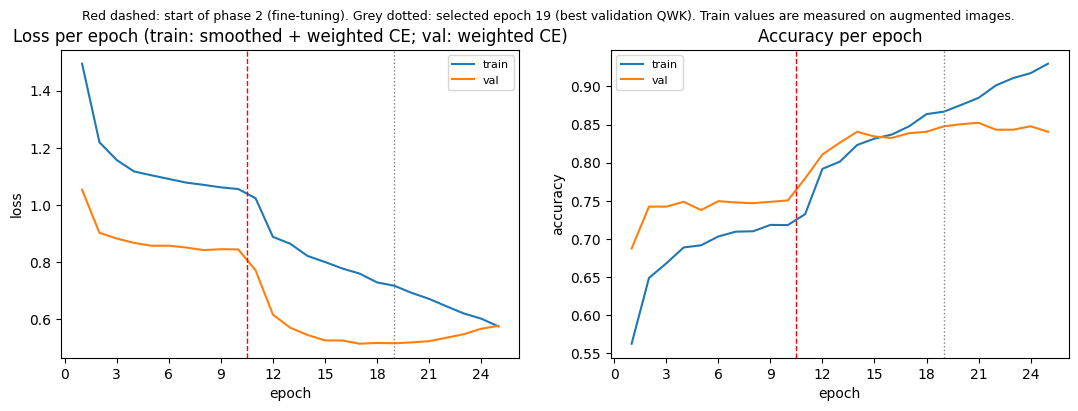

,epoch,phase,train_loss,val_loss,train_lesion_loss,train_acc,val_acc,val_macro_f1,val_qwk,lr,minutes
0,1,1,1.4946,1.0526,0.4067,0.5625,0.6874,0.5552,0.7590,9.76e-04,4.2145
1,2,1,1.2192,0.9016,0.3347,0.6488,0.7423,0.5697,0.7942,9.05e-04,3.4224
2,3,1,1.1566,0.8815,0.3197,0.6680,0.7423,0.5580,0.8003,7.94e-04,3.4254
3,4,1,1.1167,0.8661,0.3094,0.6888,0.7486,0.5722,0.8116,6.55e-04,3.4344
4,5,1,1.1033,0.8562,0.3047,0.6916,0.7378,0.5538,0.8115,5.00e-04,3.4390
5,6,1,1.0905,0.8564,0.3015,0.7032,0.7495,0.5621,0.8218,3.45e-04,3.4337
6,7,1,1.0777,0.8500,0.2994,0.7095,0.7477,0.5707,0.8203,2.06e-04,3.4346
7,8,1,1.0698,0.8410,0.2958,0.7100,0.7468,0.5795,0.8217,9.55e-05,3.4281
8,9,1,1.0610,0.8440,0.2950,0.7184,0.7486,0.5840,0.8207,2.45e-05,3.4274
9,10,1,1.0551,0.8434,0.2957,0.7181,0.7505,0.5835,0.8228,0.00e+00,3.4310


In [13]:
if hist is None:
    print("No training history available (weights loaded without history.csv).")
else:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    for split in ("train", "val"):
        axs[0].plot(hist.epoch, hist[f"{split}_loss"], label=split)
        axs[1].plot(hist.epoch, hist[f"{split}_acc"], label=split)
    axs[0].set_title("Loss per epoch (train: smoothed + weighted CE; val: weighted CE)"); axs[0].set_ylabel("loss")
    axs[1].set_title("Accuracy per epoch"); axs[1].set_ylabel("accuracy")
    for ax in axs:
        ax.axvline(best_ep, color="grey", ls=":", lw=1); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
        ax.axvline(hist.loc[hist.phase == 1, "epoch"].max() + 0.5, color="red", ls="--", lw=1)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.suptitle(f"Red dashed: start of phase 2 (fine-tuning). Grey dotted: selected epoch {best_ep} (best validation QWK). "
                 "Train values are measured on augmented images.",
                 fontsize=9)
    savefig("11_training_curves")
    display(hist.round(4).assign(lr=hist.lr.map(lambda v: f"{v:.2e}")))

## 7. Test evaluation
Accuracy, macro-F1 and QWK with bootstrap 95 % CIs, plus a check without duplicated images.

In [14]:
set_phase(2)                                                       # same variable layout as when saved
model.load_weights(str(WEIGHTS))                                   # weights of the epoch selected on validation
logits_te, y_te = predict(make_ds(te_df, False))
logits_va, y_va = predict(make_ds(va_df, False))
pred = logits_te.argmax(1)

rng = np.random.default_rng(0); boot = []
for _ in range(CFG["n_bootstrap"]):
    i = rng.integers(0, len(y_te), len(y_te)); boot.append(scores(y_te[i], pred[i]))
boot = pd.DataFrame(boot)
res = pd.DataFrame({"value": scores(y_te, pred), "95% CI low": boot.quantile(0.025), "95% CI high": boot.quantile(0.975)})
display(res.round(3)); res.to_csv(OUT_DIR / "test_metrics.csv")
dup = te_df.test_dup_of_train.values
print(f"Without the {dup.sum()} test images duplicated in train:",
      {k: round(v, 3) for k, v in scores(y_te[~dup], pred[~dup]).items()})

,value,95% CI low,95% CI high
accuracy,0.851,0.837,0.866
macro_f1,0.770,0.745,0.795
qwk,0.930,0.920,0.939


Without the 45 test images duplicated in train: {'accuracy': 0.848, 'macro_f1': 0.77, 'qwk': np.float64(0.929)}


### 7.1 Confusion matrix
Confusion matrix and per-class report.

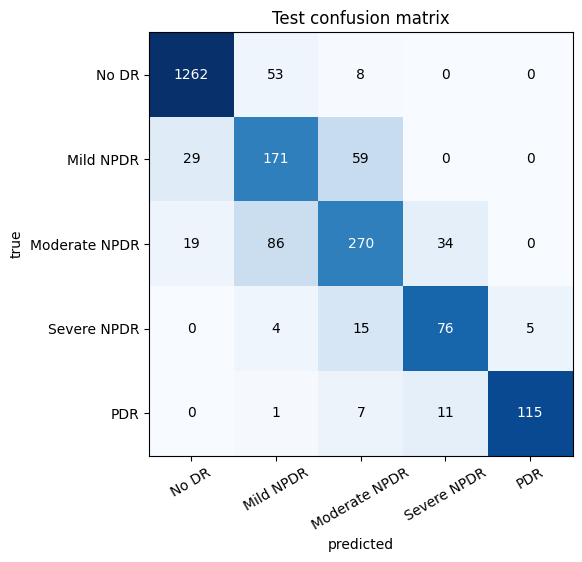

               precision    recall  f1-score   support

        No DR      0.963     0.954     0.959      1323
    Mild NPDR      0.543     0.660     0.596       259
Moderate NPDR      0.752     0.660     0.703       409
  Severe NPDR      0.628     0.760     0.688       100
          PDR      0.958     0.858     0.906       134

     accuracy                          0.851      2225
    macro avg      0.769     0.778     0.770      2225
 weighted avg      0.860     0.851     0.854      2225



In [15]:
cm = confusion_matrix(y_te, pred, labels=range(K))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
for (r, c), v in np.ndenumerate(cm):
    ax.text(c, r, v, ha="center", va="center", color="white" if v > cm.sum(1)[r] * 0.6 else "black")
ax.set_xticks(range(K), GRADES, rotation=30); ax.set_yticks(range(K), GRADES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Test confusion matrix")
savefig("12_confusion_matrix")
print(classification_report(y_te, pred, labels=range(K), target_names=GRADES, digits=3, zero_division=0))

## 8. Error analysis
Under-/over-grading, referable-DR sensitivity, performance by sharpness and worst errors.

under-graded: 7.7% | over-graded: 7.1% | off by >= 2 grades: 1.8%
referable DR (grade >= 2) sensitivity: 0.829 | specificity: 0.958 | missed PDR: 19 / 134


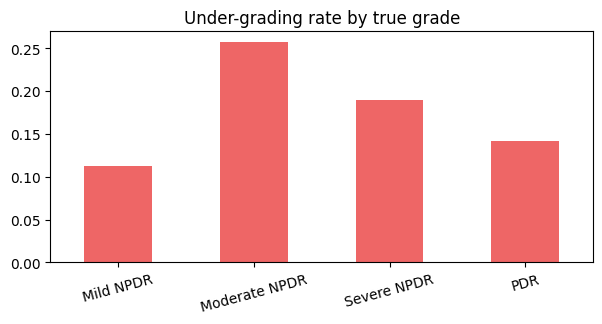

,accuracy,macro_f1,qwk
image sharpness tertile,,,
low,0.799,0.747,0.921
mid,0.850,0.777,0.908
high,0.904,0.779,0.942


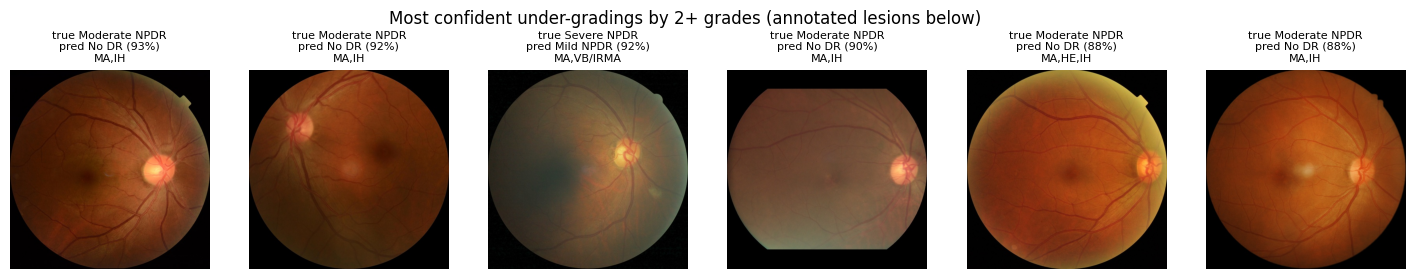

In [16]:
err = pred - y_te
print(f"under-graded: {(err < 0).mean():.1%} | over-graded: {(err > 0).mean():.1%} | off by >= 2 grades: {(abs(err) >= 2).mean():.1%}")
print(f"referable DR (grade >= 2) sensitivity: {((pred >= 2) & (y_te >= 2)).sum() / max((y_te >= 2).sum(), 1):.3f} | "
      f"specificity: {((pred < 2) & (y_te < 2)).sum() / max((y_te < 2).sum(), 1):.3f} | "
      f"missed PDR: {((y_te == 4) & (pred < 4)).sum()} / {(y_te == 4).sum()}")
pd.Series([(pred[y_te == g] < g).mean() for g in range(1, K)], index=GRADES[1:]).plot.bar(
    figsize=(7, 3), rot=15, color="#ee6666", title="Under-grading rate by true grade")
savefig("13_undergrading")
tert = pd.qcut(te_df.sharpness, 3, labels=["low", "mid", "high"]).values
display(pd.DataFrame({t: scores(y_te[tert == t], pred[tert == t]) for t in ["low", "mid", "high"]}).T.round(3)
        .rename_axis("image sharpness tertile"))
prob_te = softmax(logits_te, axis=1)
worst = np.where(err <= -2)[0]
worst = worst[np.argsort(-prob_te[worst].max(1))][:6]
if len(worst):
    fig, axs = plt.subplots(1, len(worst), figsize=(3 * len(worst), 3.3), squeeze=False)
    for ax, i in zip(axs[0], worst):
        ax.imshow(Image.open(IMG_DIR / te_df.file[i])); ax.axis("off")
        lesions = ",".join(l for l in LESIONS if te_df.loc[i, l]) or "none"
        ax.set_title(f"true {GRADES[y_te[i]]}\npred {GRADES[pred[i]]} ({prob_te[i].max():.0%})\n{lesions}", fontsize=8)
    plt.suptitle("Most confident under-gradings by 2+ grades (annotated lesions below)"); savefig("14_errors")

## 9. Reliability
**Calibration:** do the predicted probabilities match how often the model is right? A temperature `T` is fitted
on the validation set (temperature scaling).
**Referral:** the least-confident 20 % of cases (threshold set on validation) are flagged for human review.
**Image quality:** metrics on blurred and darkened copies of the test images

In [17]:
def ece(prob, y, bins=10):
    conf, ok = prob.max(1), prob.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1)
    return sum(((conf > a) & (conf <= b)).mean() * abs(ok[(conf > a) & (conf <= b)].mean() - conf[(conf > a) & (conf <= b)].mean())
               for a, b in zip(edges[:-1], edges[1:]) if ((conf > a) & (conf <= b)).any())


nll = lambda logits, y: -log_softmax(logits, axis=1)[np.arange(len(y)), y].mean()
temps = np.linspace(0.5, 5, 46)
TEMP = temps[np.argmin([nll(logits_va / t, y_va) for t in temps])]
prob_cal = softmax(logits_te / TEMP, axis=1)
print(f"temperature T = {TEMP:.2f} | ECE before {ece(prob_te, y_te):.3f} -> after {ece(prob_cal, y_te):.3f}")

conf = prob_cal.max(1)
tau = np.quantile(softmax(logits_va / TEMP, axis=1).max(1), CFG["referral_rate"])
refer = conf < tau
print(f"referred for review: {refer.mean():.1%} | accuracy of referred {(pred[refer] == y_te[refer]).mean():.3f} "
      f"vs accepted {(pred[~refer] == y_te[~refer]).mean():.3f} | errors caught by referral: "
      f"{(pred[refer] != y_te[refer]).sum() / max((pred != y_te).sum(), 1):.1%}")


def gaussian_blur(img, sigma):
    """Gaussian blur of a float32 HxWx3 image (TensorFlow equivalent of PIL's GaussianBlur)."""
    k = int(2 * round(3 * sigma) + 1)
    x = tf.range(k, dtype=tf.float32) - (k - 1) / 2
    g = tf.exp(-x ** 2 / (2 * sigma ** 2)); g = g / tf.reduce_sum(g)
    kernel = tf.tile((g[:, None] * g[None, :])[:, :, None, None], [1, 1, 3, 1])
    return tf.nn.depthwise_conv2d(img[None], kernel, [1, 1, 1, 1], "SAME")[0]


rows = []
for name, fn in {"clean": None, "blur": lambda im: gaussian_blur(im, 3 * SIZE / 512),
                 "dark": lambda im: tf.clip_by_value(im * 0.6, 0.0, 255.0)}.items():
    lg, yy = predict(make_ds(te_df, False, perturb=fn))
    rows.append(dict(condition=name, **scores(yy, lg.argmax(1))))
display(pd.DataFrame(rows).set_index("condition").round(3))

temperature T = 0.80 | ECE before 0.038 -> after 0.032
referred for review: 20.5% | accuracy of referred 0.572 vs accepted 0.923 | errors caught by referral: 58.9%


,accuracy,macro_f1,qwk
condition,,,
clean,0.851,0.770,0.930
blur,0.791,0.675,0.871
dark,0.852,0.771,0.929


## 10. Explainability
### 10.1 Grad-CAM
Heatmaps for the predicted grade next to the original image.

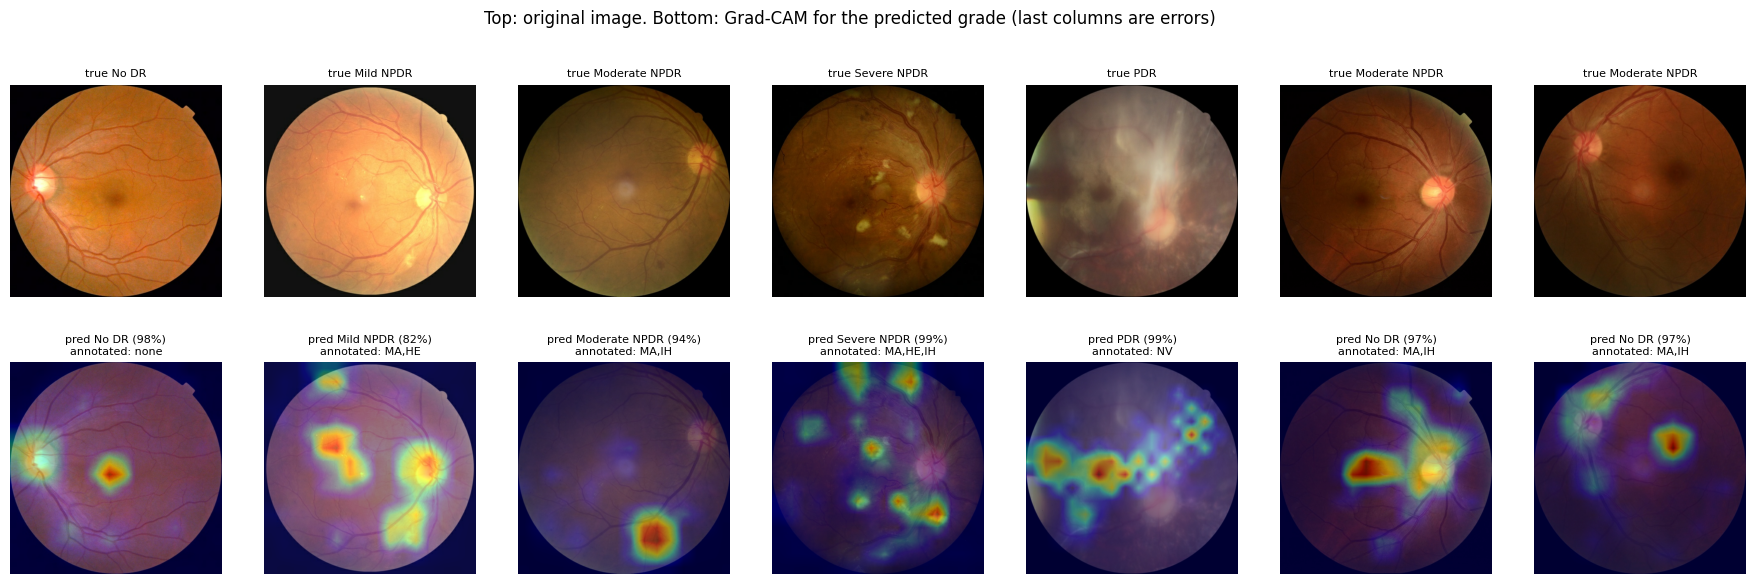

In [18]:
grad_model = keras.Model(model.input, [model.get_layer("top_activation").output,
                                        model.get_layer("head_out").output, model.get_layer("head_lesion_out").output])


def gradcam(x, cls, output="grade"):
    """Grad-CAM map in [0, 1] for one preprocessed image batch x (1, H, W, 3).
    output="grade": evidence for grade `cls`; output="lesion": evidence for lesion index `cls`."""
    with tf.GradientTape() as tape:
        fmap, g_logits, l_logits = grad_model(x, training=False)
        score = (g_logits if output == "grade" else l_logits)[:, cls]
    g = tape.gradient(score, fmap)
    g, fmap = tf.cast(g, tf.float32), tf.cast(fmap, tf.float32)       # mixed precision: compute the map in float32
    cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(g, axis=(1, 2), keepdims=True) * fmap, axis=-1))[0]
    cam = tf.image.resize(cam[..., None], (SIZE, SIZE))[..., 0]
    return (cam / (tf.reduce_max(cam) + 1e-8)).numpy()


show = [te_df[(te_df.grade == g) & (pred == g)].index[0] for g in range(K) if ((te_df.grade == g) & (pred == g)).any()]
show += list(worst[:2])
fig, axs = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6.6), squeeze=False)
for j, i in enumerate(show):
    img = load_image(str(IMG_DIR / te_df.file[i]))
    cam = gradcam(preprocess(img)[None], int(pred[i]))
    rgb = np.clip(img.numpy() / 255.0, 0, 1)
    axs[0, j].imshow(rgb); axs[0, j].set_title(f"true {GRADES[y_te[i]]}", fontsize=8)
    axs[1, j].imshow(rgb); axs[1, j].imshow(cam, cmap="jet", alpha=0.4)
    lesions = ",".join(l for l in LESIONS if te_df.loc[i, l]) or "none"
    axs[1, j].set_title(f"pred {GRADES[pred[i]]} ({prob_cal[i].max():.0%})\nannotated: {lesions}", fontsize=8)
    for ax in axs[:, j]: ax.axis("off")
plt.suptitle("Top: original image. Bottom: Grad-CAM for the predicted grade (last columns are errors)")
savefig("15_gradcam")

### 10.2 Lesion detection: Clinical interpretation
Per-lesion AUROC, AP, sensitivity and specificity against the MMRDR annotations.

,test_prevalence,AUROC,AP,sensitivity,specificity,F1,threshold
lesion,,,,,,,
MA,0.394,0.986,0.979,0.897,0.961,0.917,0.62
HE,0.227,0.961,0.883,0.858,0.914,0.799,0.54
IH,0.230,0.954,0.851,0.779,0.930,0.774,0.63
VB/IRMA,0.019,0.950,0.271,0.442,0.973,0.317,0.64
NV,0.054,0.994,0.944,0.926,0.987,0.858,0.29
VH,0.024,0.998,0.915,0.906,0.992,0.814,0.73
RD,0.009,0.997,0.804,0.667,0.999,0.737,0.86


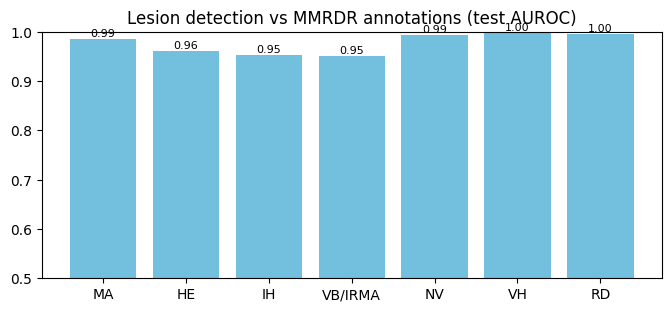

In [19]:
def predict_lesions(ds):
    """Lesion probabilities (sigmoid) from a single view of each image."""
    probs = []
    for x, *_ in ds:
        probs.append(1 / (1 + np.exp(-infer_all(x)["lesion"].numpy().astype(np.float32))))
    return np.concatenate(probs)


les_va, les_te = predict_lesions(make_ds(va_df, False)), predict_lesions(make_ds(te_df, False))
yl_va, yl_te = va_df[LESIONS].values, te_df[LESIONS].values
grid = np.linspace(0.05, 0.95, 91)
LES_THR = np.array([grid[np.argmax([f1_score(yl_va[:, j], les_va[:, j] >= t, zero_division=0) for t in grid])]
                    if yl_va[:, j].any() else 0.5 for j in range(len(LESIONS))])
les_hat = (les_te >= LES_THR[None]).astype(int)
rows = []
for j, l in enumerate(LESIONS):
    yt, pj, hj = yl_te[:, j], les_te[:, j], les_hat[:, j]
    both = 0 < yt.sum() < len(yt)
    rows.append(dict(lesion=l, test_prevalence=yt.mean(), AUROC=roc_auc_score(yt, pj) if both else np.nan,
                     AP=average_precision_score(yt, pj) if yt.sum() else np.nan,
                     sensitivity=(hj[yt == 1] == 1).mean() if yt.sum() else np.nan,
                     specificity=(hj[yt == 0] == 0).mean() if (yt == 0).any() else np.nan,
                     F1=f1_score(yt, hj, zero_division=0), threshold=LES_THR[j]))
lesion_tbl = pd.DataFrame(rows).set_index("lesion")
display(lesion_tbl.round(3)); lesion_tbl.to_csv(OUT_DIR / "lesion_detection.csv")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(LESIONS, lesion_tbl.AUROC, color="#73c0de"); ax.set_ylim(0.5, 1)
for k_, v in enumerate(lesion_tbl.AUROC):
    ax.text(k_, v + 0.005, f"{v:.2f}", ha="center", fontsize=8)
ax.set_title("Lesion detection vs MMRDR annotations (test AUROC)"); savefig("16_lesion_auroc")

### 10.3 Grade–lesion consistency
Flag predictions that contradict the model's own strongly detected lesions.

In [20]:
T_STRONG = np.array([np.quantile(les_va[yl_va[:, j] == 0, j], 0.95) if (yl_va[:, j] == 0).any() else 1.0
                     for j in range(len(LESIONS))])
print("strong-evidence thresholds (95% specificity on validation):", dict(zip(LESIONS, T_STRONG.round(2))))
flags_te = rule_violations(pred, (les_te >= T_STRONG[None]).astype(int))
print("sanity check, rules applied to the TRUE test grades and TRUE lesions:",
      int(rule_violations(y_te, yl_te).any(axis=1).sum()), "violations (expected 0)")
incons = flags_te.any(axis=1).values
wrong = pred != y_te
print("inconsistency flags on test:", flags_te.sum().to_dict())
if incons.any() and (~incons).any():
    print(f"inconsistent predictions: {incons.mean():.1%} of test images | error rate {wrong[incons].mean():.2f} "
          f"vs {wrong[~incons].mean():.2f} for consistent ones")
    refer_both = refer | incons
    print(f"referral: confidence only catches {(wrong & refer).sum() / max(wrong.sum(), 1):.1%} of errors "
          f"({refer.mean():.1%} referred) | confidence OR inconsistency catches {(wrong & refer_both).sum() / max(wrong.sum(), 1):.1%} "
          f"({refer_both.mean():.1%} referred)")
    missed_pdr = (y_te == 4) & (pred < 4)
    print(f"missed PDR cases flagged by the lesion check: {(missed_pdr & incons).sum()} / {missed_pdr.sum()}")

ih = LESIONS.index("IH")
mm = np.isin(y_te, [1, 2])
display(pd.DataFrame({"mean P(IH)": pd.Series(les_te[mm, ih]).groupby(y_te[mm]).mean().rename(index={1: "true Mild", 2: "true Moderate"}),
                      "IH annotated (rate)": pd.Series(yl_te[mm, ih]).groupby(y_te[mm]).mean().rename(index={1: "true Mild", 2: "true Moderate"})}).round(3))

strong-evidence thresholds (95% specificity on validation): {'MA': np.float32(0.43), 'HE': np.float32(0.62), 'IH': np.float32(0.72), 'VB/IRMA': np.float32(0.53), 'NV': np.float32(0.03), 'VH': np.float32(0.01), 'RD': np.float32(0.01)}
sanity check, rules applied to the TRUE test grades and TRUE lesions: 0 violations (expected 0)
inconsistency flags on test: {'under_graded_vs_lesions': 142, 'dr_without_lesions': 19, 'pdr_without_pdr_lesion': 0, 'npdr_without_ma': 19, 'no_dr_with_lesions': 11}
inconsistent predictions: 7.2% of test images | error rate 0.42 vs 0.13 for consistent ones
referral: confidence only catches 58.9% of errors (20.5% referred) | confidence OR inconsistency catches 64.7% (23.2% referred)
missed PDR cases flagged by the lesion check: 17 / 19


,mean P(IH),IH annotated (rate)
true Mild,0.330,0.000
true Moderate,0.708,0.866


### 10.4 Lesion-specific Grad-CAM
Grade map and maps for the most probable lesions on example cases.

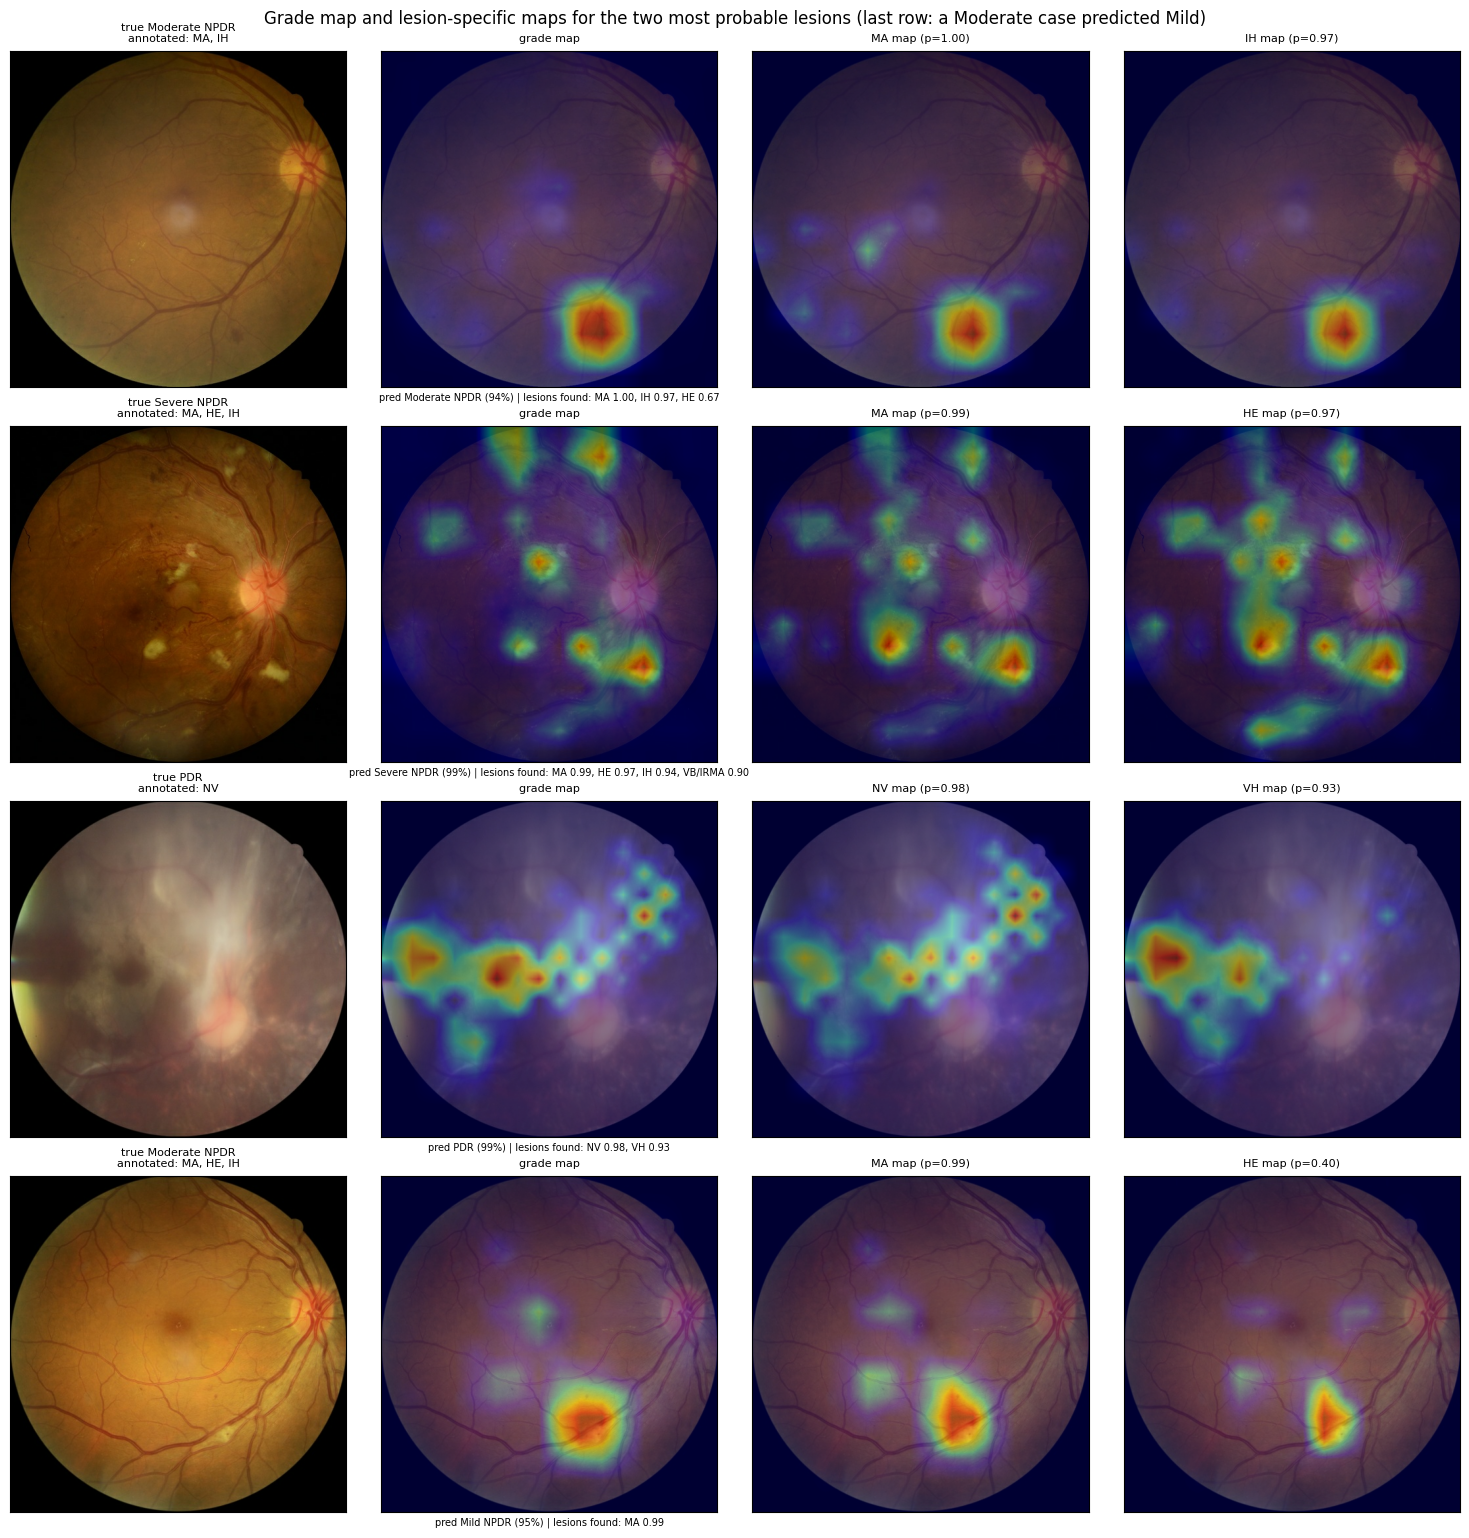

In [21]:
def explanation_text(i):
    """Plain-language explanation built from the model's own outputs (not ground truth)."""
    det = [f"{LESIONS[j]} {les_te[i, j]:.2f}" for j in np.argsort(-les_te[i]) if les_hat[i, j]]
    return f"pred {GRADES[pred[i]]} ({prob_cal[i].max():.0%}) | lesions found: {', '.join(det) or 'none'}"


cases = []
for g_, need in ((2, "IH"), (3, "IH"), (4, "NV")):                  # correct, lesion-annotated examples
    c_ = te_df[(te_df.grade == g_) & (pred == g_) & (te_df[need] == 1)].index
    if len(c_): cases.append(c_[0])
c_ = te_df[(te_df.grade == 2) & (pred == 1)].index                    # a Moderate case under-graded as Mild
if len(c_): cases.append(c_[0])
fig, axs = plt.subplots(len(cases), 4, figsize=(15, 3.9 * max(len(cases), 1)), squeeze=False)
for r_, i in enumerate(cases):
    img = load_image(str(IMG_DIR / te_df.file[i])); x = preprocess(img)[None]
    rgb = np.clip(img.numpy() / 255.0, 0, 1)
    top = list(np.argsort(-les_te[i])[:2])
    ann = ", ".join(l for l in LESIONS if te_df.loc[i, l]) or "none"
    axs[r_, 0].imshow(rgb); axs[r_, 0].set_title(f"true {GRADES[y_te[i]]}\nannotated: {ann}", fontsize=8)
    for k_, (title, cam_) in enumerate([("grade map", gradcam(x, int(pred[i]), "grade"))] +
                                       [(f"{LESIONS[j]} map (p={les_te[i, j]:.2f})", gradcam(x, int(j), "lesion")) for j in top]):
        axs[r_, k_ + 1].imshow(rgb); axs[r_, k_ + 1].imshow(cam_, cmap="jet", alpha=0.4); axs[r_, k_ + 1].set_title(title, fontsize=8)
    axs[r_, 1].set_xlabel(explanation_text(i), fontsize=7)
    for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
plt.suptitle("Grade map and lesion-specific maps for the two most probable lesions (last row: a Moderate case predicted Mild)")
plt.tight_layout(); savefig("17_lesion_gradcam")

## 11. Summary
Final test metrics and output locations.

In [22]:
s = scores(y_te, pred)
print(f"LG-EffNetV2-S (grade + lesion heads, two-phase, EMA, label smoothing) | selected epoch {best_ep} / {len(hist)} (phase {best_phase}) | test accuracy {s['accuracy']:.3f}, "
      f"macro-F1 {s['macro_f1']:.3f}, QWK {s['qwk']:.3f}")
print(f"Weights: {WEIGHTS} | metrics: {OUT_DIR / 'test_metrics.csv'} | figures: {OUT_DIR / 'figures'}")
print(f"lesion detection: mean AUROC {lesion_tbl.AUROC.mean():.3f} (IH {lesion_tbl.loc['IH', 'AUROC']:.3f}, NV {lesion_tbl.loc['NV', 'AUROC']:.3f})")

LG-EffNetV2-S (grade + lesion heads, two-phase, EMA, label smoothing) | selected epoch 19 / 25 (phase 2) | test accuracy 0.851, macro-F1 0.770, QWK 0.930
Weights: /kaggle/input/datasets/mariajabeen01/effnetv2s-v3-dr-weights/effnetv2s_v3_tf_dr.weights.h5 | metrics: /kaggle/working/outputs_effnetv2s_v3_tf/test_metrics.csv | figures: /kaggle/working/outputs_effnetv2s_v3_tf/figures
lesion detection: mean AUROC 0.977 (IH 0.954, NV 0.994)


**Limitations:** image-level split without patient IDs, some test duplicates of training images, single data source, few Severe NPDR/PDR test images. Research prototype, not a clinical tool.